In [1]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv(r"D:\Loan_data_0\loan_approval_dataset.csv")

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.shape

(4269, 13)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [6]:
df.drop(columns=['loan_id'], inplace=True)

In [7]:
# Strip spaces from column names
df.columns = df.columns.str.strip()

In [8]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

# Apply encoding
df['education'] = le.fit_transform(df['education'])
df['self_employed'] = le.fit_transform(df['self_employed'])


In [9]:
df.head(2)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected


In [10]:
# Separate features and target
X = df.drop(columns=['loan_status'])
y = df['loan_status']

In [11]:
# Normalize numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [12]:
from sklearn.ensemble import RandomForestClassifier
rfr = RandomForestClassifier(n_estimators = 120)
rfr.fit(X_train,y_train)

RandomForestClassifier(n_estimators=120)

In [13]:
rfr.score(X_test,y_test)

0.9824355971896955

In [14]:
y_pred_rf = rfr.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

    Approved       0.98      0.99      0.99       536
    Rejected       0.98      0.97      0.98       318

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

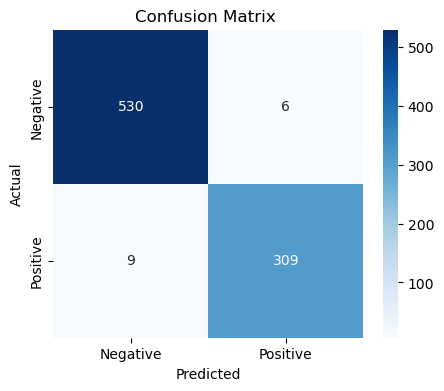

In [16]:
cm = confusion_matrix(y_test, y_pred_rf)


plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix ")
plt.show()

In [17]:
import numpy as np

new_data = np.array([[2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000]])
new_data_scaled = scaler.transform(new_data)

predicted_output = rfr.predict(new_data_scaled)
print("Predicted Output:", predicted_output)

Predicted Output: [' Approved']


C:\Users\chinm\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [18]:
# import pickle
# with open("sugar_1.pkl", "wb") as file:
#     pickle.dump(rfr, file)

In [19]:
# import joblib

# # Save the scaler
# joblib.dump(scaler, "scaler.pkl")

# # Save label encoders
# label_encoders = {
#     'education': le.fit(df['education']),
#     'self_employed': le.fit(df['self_employed'])
# }
# joblib.dump(label_encoders, "label_encoders.pkl")